**Lets make a PCA: What are the territorial, fiscal, and rural financing profiles of Colombian municipalities, and how is violence against social leaders distributed among them?**



In [ ]:
#Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## 1. Database

The data come from the Panel Municipal del CEDE (Universidad de los Andes): *Características generales*, *Buen Gobierno* and *Agricultura y Tierra*, merged with killings of social leaders reported by **Somos Defensores** and information of ANT. This is de data of a proyect in wich i have been working. Each row is a municipality-year. For the PCA I use the average of 2016–2022 for each municipality.

In [2]:
panel_municipal_tierras = pd.read_csv('panel_tierras_violencia_final.csv')
panel_municipal_tierras

,cod_municipio,anio,cod_departamento,nombre_departamento,nombre_municipio,pobl_rur,pobl_urb,pobl_tot,discapital,altura,...,SGP_total_mill,vrf_peq_pc,vrf_grande_pc,vrf_mediano_pc,vrf_credito_total_pc,tasa_acciones_belicas,ln_acciones_belicas,tasa_lideres_asesinados_SD,tasa_lideres_rurales_SD,ln_lideres_asesinados_SD
0,5001,2012,5,Antioquia,Medellín,31877,2361134,2393011,0.000000,1475,...,759888.128694,0.503819,73.067748,4.308681,77.880248,0.125365,1.386294,0.376095,0.0,2.302585
1,5001,2013,5,Antioquia,Medellín,31092,2386233,2417325,0.000000,1475,...,814131.823457,0.543175,133.074548,5.181548,138.799272,0.000000,0.000000,0.124104,0.0,1.386294
2,5001,2014,5,Antioquia,Medellín,30358,2410765,2441123,0.000000,1475,...,853980.497243,0.349729,141.734674,3.320904,145.405306,0.000000,0.000000,0.000000,0.0,0.000000
3,5001,2015,5,Antioquia,Medellín,29675,2434647,2464322,0.000000,1475,...,891653.569917,0.367260,261.030448,6.727617,268.125325,0.000000,0.000000,0.162316,0.0,1.609438
4,5001,2016,5,Antioquia,Medellín,29043,2457680,2486723,0.000000,1475,...,963269.289852,0.589629,355.891117,15.655034,372.135780,0.000000,0.000000,0.040214,0.0,0.693147
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13447,99773,2019,99,Vichada,Cumaribo,73053,3143,76196,91.518799,161,...,36651.380566,7.079339,0.000000,12.535045,19.614384,0.000000,0.000000,2.624810,0.0,1.098612
13448,99773,2020,99,Vichada,Cumaribo,75490,3373,78863,91.518799,161,...,42002.805296,14.752022,0.000000,22.576581,37.328603,0.000000,0.000000,1.268022,0.0,0.693147
13449,99773,2021,99,Vichada,Cumaribo,76648,3336,79984,91.518799,161,...,46149.617256,14.112262,70.639128,12.631980,97.383370,0.000000,0.000000,0.000000,0.0,0.000000
13450,99773,2022,99,Vichada,Cumaribo,77681,3156,80837,91.518799,161,...,51291.796421,15.393279,105.656060,8.959581,130.008920,0.000000,0.000000,0.000000,0.0,0.000000


## 2. Variable selection


| Variable | Description | Source / Definition | Unit |
|---|---|---|---|
| `cod_municipio` | Municipality identifier | DIVIPOLA 5-digit code (DANE) | Code |
| `anio` | Year of observation | — | Year |
| `cod_departamento` | Department identifier | DIVIPOLA 2-digit code (DANE) | Code |
| `nombre_departamento` | Department name | DANE | Text |
| `nombre_municipio` | Municipality name | DANE | Text |
| `pobl_tot` | Total population | DANE population projections | Persons |
| `pobl_rur` | Rural population (outside the municipal seat, *resto*) | DANE population projections | Persons |
| `areaoficialhas` | Official municipal area | IGAC / CEDE | Hectares |
| `pdet` | Municipality included in a Development Program with a Territorial Approach (PDET), created by the 2016 Peace Agreement | Decree 893/2017 (170 municipalities) | Dummy (1 = PDET) |
| `pnis` | Municipality included in the National Comprehensive Program for the Substitution of Illicit Crops (PNIS) | Decree 896/2017 | Dummy (1 = PNIS) |
| `n_lideres_asesinados_SD` | Number of social leaders and human rights defenders killed | Programa Somos Defensores | Count |
| `y_corr` | Current revenue: tax revenue, non-tax revenue and current transfers | `y_corr_tribut + y_no_tribut + y_transf` (CEDE) | Millions COP (current) |
| `y_transf` | Current transfers received by the municipality (component of current revenue) | CEDE fiscal panel | Millions COP |
| `y_cap_regalias` | Royalty revenue from extraction of non-renewable natural resources (component of capital revenue) | CEDE fiscal panel | Millions COP |
| `y_cap_transf` | Capital transfers received by the municipality, earmarked for investment | Capital transfers from SGP, SGR and others (CEDE) | Millions COP |
| `g_cap_FBKF` | Public capital expenditure on gross fixed capital formation (municipal investment in infrastructure and fixed assets) | CEDE fiscal panel | Millions COP |
| `vrf_peq_productor` | FINAGRO agricultural credit disbursed to small producers | FINAGRO / CEDE | Millions COP |
| `vrf_mediano_productor` | FINAGRO agricultural credit disbursed to medium producers | FINAGRO / CEDE | Millions COP |
| `vrf_grande_productor` | FINAGRO agricultural credit disbursed to large producers | FINAGRO / CEDE | Millions COP |
| `vrf_mujer_rural` | FINAGRO agricultural credit disbursed to rural women producers | FINAGRO / CEDE | Millions COP |
| `DF_desemp_fisc` | Fiscal Performance Index (*Índice de Desempeño Fiscal*) | DNP | Index (0–100) |
| `MDM` | Municipal Performance Measure (*Medición del Desempeño Municipal*): management capacity and development outcomes | DNP (available from 2016) | Index (0–100) |
| `indrural` | Rurality index: share of the population living in rural areas | `pobl_rur / pobl_tot` (CEDE) | Ratio (0–1) |
| `discapital` | Straight-line distance from the municipal seat to the department capital | CEDE | Kilometers |
| `altura` | Altitude of the municipal seat | IGAC / CEDE | Meters above sea level |


In [63]:
#Selecting some variables before PCA
df = panel_municipal_tierras[[
    "cod_municipio",
    "anio",
    "cod_departamento",
    "nombre_departamento",
    "nombre_municipio",
    "pobl_tot",
    "pobl_rur",
    "areaoficialhas",
    "pdet",
    "pnis",
    "n_lideres_asesinados_SD",
    "y_corr",
    "y_transf",
    "y_cap_regalias",
    "y_cap_transf",
    "g_cap_FBKF",
    "vrf_peq_productor",
    "vrf_mediano_productor",
    "vrf_grande_productor",
    "vrf_mujer_rural",
    "DF_desemp_fisc",
    "MDM",
    "indrural",
    "discapital",
    "altura"
]]
df

,cod_municipio,anio,cod_departamento,nombre_departamento,nombre_municipio,pobl_tot,pobl_rur,areaoficialhas,pdet,pnis,...,g_cap_FBKF,vrf_peq_productor,vrf_mediano_productor,vrf_grande_productor,vrf_mujer_rural,DF_desemp_fisc,MDM,indrural,discapital,altura
0,5001,2012,5,Antioquia,Medellín,2393011,31877,38700,0,0,...,1.135220e+06,1205.644110,10310.721370,174851.923943,0.000000,83.220000,NaN,0.013321,0.000000,1475
1,5001,2013,5,Antioquia,Medellín,2417325,31092,38700,0,0,...,1.320714e+06,1313.031363,12525.486255,321684.432108,0.000000,84.820000,NaN,0.012862,0.000000,1475
2,5001,2014,5,Antioquia,Medellín,2441123,30358,38700,0,0,...,2.167382e+06,853.731017,8106.734129,345991.771595,0.000000,85.497871,NaN,0.012436,0.000000,1475
3,5001,2015,5,Antioquia,Medellín,2464322,29675,38700,0,0,...,1.010917e+06,905.045975,16579.013861,643263.076327,0.000000,83.733107,NaN,0.012042,0.000000,1475
4,5001,2016,5,Antioquia,Medellín,2486723,29043,38700,0,0,...,8.231036e+05,1466.244519,38929.733095,885002.626830,0.000000,81.150000,80.777468,0.011679,0.000000,1475
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13447,99773,2019,99,Vichada,Cumaribo,76196,73053,6567400,0,1,...,9.004020e+03,539.417321,955.120296,0.000000,0.000000,68.759667,41.512946,0.958751,91.518799,161
13448,99773,2020,99,Vichada,Cumaribo,78863,75490,6567400,0,1,...,6.195976e+03,1163.388749,1780.456906,0.000000,0.000000,62.680000,20.255919,0.957230,91.518799,161
13449,99773,2021,99,Vichada,Cumaribo,79984,76648,6567400,0,1,...,6.587326e+03,1128.755169,1010.356261,5650.000000,26.500000,24.066327,39.888363,0.958292,91.518799,161
13450,99773,2022,99,Vichada,Cumaribo,80837,77681,6567400,0,1,...,1.339549e+04,1244.346527,724.265625,8540.918945,76.800003,32.114137,46.181302,0.960958,91.518799,161


In [5]:
#Selecting the years 2016–2022 and averaging them by municipality
df_years = df[df["anio"].between(2016, 2022)].sort_values(["cod_municipio", "anio"])

df_2016_2022 = df_years.groupby("cod_municipio", as_index=False).agg(
    cod_departamento=("cod_departamento", "last"),
    nombre_departamento=("nombre_departamento", "last"),
    nombre_municipio=("nombre_municipio", "last"),
    **{col: (col, "mean") for col in df.columns[5:]}
)
df_2016_2022.isna().sum()

cod_municipio               0
cod_departamento            0
nombre_departamento         0
nombre_municipio            0
pobl_tot                    0
pobl_rur                    0
areaoficialhas              0
pdet                        0
pnis                        0
n_lideres_asesinados_SD     0
y_corr                     19
y_transf                   19
y_cap_regalias             19
y_cap_transf               19
g_cap_FBKF                 19
vrf_peq_productor           0
vrf_mediano_productor       0
vrf_grande_productor        0
vrf_mujer_rural             0
DF_desemp_fisc             19
MDM                        19
indrural                    0
discapital                  0
altura                      0
dtype: int64

In [7]:
rows_with_na = df_2016_2022.isna().any(axis=1)

print("Municipios con algún faltante:", rows_with_na.sum())

df_2016_2022.loc[
    rows_with_na,
    ["cod_municipio", "nombre_departamento", "nombre_municipio"]]

Municipios con algún faltante: 19


,cod_municipio,nombre_departamento,nombre_municipio
1086,88001,San Andrés y Providencia,San Andrés
1089,91263,Amazonas,El Encanto (CD)
1090,91405,Amazonas,La Chorrera (CD)
1091,91407,Amazonas,La Pedrera (CD)
1092,91430,Amazonas,La Victoria (CD)
1093,91460,Amazonas,Miriti - Paraná (CD)
1094,91530,Amazonas,Puerto Alegría (CD)
1095,91536,Amazonas,Puerto Arica (CD)
1097,91669,Amazonas,Puerto Santander (CD)
1098,91798,Amazonas,Tarapacá (CD)


In [8]:
# i define cols_needed lists the variables that enter the PCA. 

cols_needed = [
    "y_corr",
    "y_transf",
    "y_cap_regalias",
    "y_cap_transf",
    "g_cap_FBKF",
    "DF_desemp_fisc",
    "MDM"
]

df_2016_2022_needed = df_2016_2022.dropna(subset=cols_needed).copy()
df_2016_2022_needed.shape

(1102, 24)

### Period: average 2016–2022

Instead of a single year, each variable is the municipality's average over 2016–2022

$$
\bar{x}_i = \frac{1}{T_i}\sum_{t=2016}^{2022} x_{it}
$$

where $T_i$ is the number of years with data for municipality $i$. 
Why an average and not a single year:

- Royalties, public investment and FINAGRO credit change a lot from one year to the next. The average describes the structural profile of each municipality and not the situation of one particular year.
- The unit of observation is still the municipality. 
- Amounts are in current pesos. Since all municipalities are averaged over the same years, inflation affects them roughly in the same proportion, and the standardization removes that common scale.

I now have the database without missing values: 1,102 municipalities. The 19 excluded units are 18 áreas no municipalizadas in Amazonas, Guainía and Vaupés plus San Andrés, which have no fiscal data in any year of the period.

### Building the indicators

Municipalities differ enormously in size (on average in 2016–2022 Medellín has 2.5 million inhabitants, Abriaquí about 2,500), so monetary totals mostly measure size. To compare them I express every monetary variable per inhabitant:

$$
x^{pc}_{i} = \frac{x_i}{\text{pop}_i}
$$

where $x_i$ is the average annual amount (millions COP) in municipality $i$ and $\text{pop}_i$ its average total population. 

Own revenue is:


$$
\text{own revenue}_i = \frac{y^{corr}_i - y^{transf}_i}{\text{pop}_i}
$$

and population density (inhabitants per $km^2$) is

$$
\text{density}_i = \frac{\text{pop}_i}{\text{area}_i / 100}
$$

because `areaoficialhas` is in hectares and 100 ha = 1 $km^2$.

In [64]:
pop = df_2016_2022_needed["pobl_tot"]


df_2016_2022_needed["densidad_poblacional"] = pop / (df_2016_2022_needed["areaoficialhas"] / 100)


df_2016_2022_needed["y_propios_pc"] = (df_2016_2022_needed["y_corr"] - df_2016_2022_needed["y_transf"]) / pop

per_capita = [
    "y_transf",
    "y_cap_transf",
    "y_cap_regalias",
    "g_cap_FBKF",
    "vrf_peq_productor",
    "vrf_mediano_productor",
    "vrf_grande_productor",
    "vrf_mujer_rural",
]
for col in per_capita:
    df_2016_2022_needed[col + "_pc"] = df_2016_2022_needed[col] / pop

df_2016_2022_needed.filter(like='_pc').head()

,y_propios_pc,y_transf_pc,y_cap_transf_pc,y_cap_regalias_pc,g_cap_FBKF_pc,vrf_peq_productor_pc,vrf_mediano_productor_pc,vrf_grande_productor_pc,vrf_mujer_rural_pc
0,0.865393,0.033793,0.625552,0.000006,0.416604,0.000941,0.034797,0.627819,0.000009
1,0.160965,0.087320,0.728776,0.038471,0.251693,0.272363,0.366385,0.101597,0.001783
2,0.254670,0.309306,1.118231,0.108749,0.770516,0.139084,0.082422,0.000000,0.001122
3,0.339562,0.257389,1.117680,0.038886,0.801402,0.093682,0.022018,0.014770,0.002682
4,0.445340,0.039078,0.403737,0.023153,0.295368,0.010985,0.084300,0.804156,0.000290


### The 15 variables of the PCA

| Block | Variable | Meaning |
|---|---|---|
| Territorial | `densidad_poblacional` | Inhabitants per km² |
| | `indrural` | Rural population / total population |
| | `discapital` | Linear distance to the departmental capital (km) |
| | `altura` | Altitude (m above sea level) |
| Fiscal | `y_propios_pc` | Own (tax + non-tax) revenue per capita |
| | `y_transf_pc` | Current transfers per capita |
| | `y_cap_transf_pc` | Capital transfers (SGP, SGR) per capita |
| | `y_cap_regalias_pc` | Royalties per capita |
| | `g_cap_FBKF_pc` | Fixed capital investment per capita |
| | `DF_desemp_fisc` | Fiscal performance index (0–100) |
| | `MDM` | Municipal performance measure (0–100) |
| Rural financing | `vrf_peq_productor_pc` | Credit disbursed to small producers per capita |
| | `vrf_mediano_productor_pc` | Credit disbursed to medium producers per capita |
| | `vrf_grande_productor_pc` | Credit disbursed to large producers per capita |
| | `vrf_mujer_rural_pc` | Credit disbursed to rural women per capita |



Most monetary variables and density are strongly skewed to the rigth: Since PCA is built on variances and correlations those few observations would dominate the components.  
Therefore i decided to apply

$$
\tilde{x}_{ij} = \ln(1 + x_{ij})
$$

The $+1$ keeps the transformation defined when $x_{ij} = 0$ (many municipalities receive no royalties or no large-producer credit), and $\ln$ compresses large values. The table compares the skewness before and after.

In [65]:
pca_variables = [
    # Territorial
    "densidad_poblacional",
    "indrural",
    "discapital",
    "altura",
    # Fiscal
    "y_propios_pc",
    "y_transf_pc",
    "y_cap_transf_pc",
    "y_cap_regalias_pc",
    "g_cap_FBKF_pc",
    "DF_desemp_fisc",
    "MDM",
    # Rural financing
    "vrf_peq_productor_pc",
    "vrf_mediano_productor_pc",
    "vrf_grande_productor_pc",
    "vrf_mujer_rural_pc",
]

log_variables = [
    "densidad_poblacional",
    "discapital",
    "y_propios_pc",
    "y_transf_pc",
    "y_cap_transf_pc",
    "y_cap_regalias_pc",
    "g_cap_FBKF_pc",
    "vrf_peq_productor_pc",
    "vrf_mediano_productor_pc",
    "vrf_grande_productor_pc",
    "vrf_mujer_rural_pc",
]

X = df_2016_2022_needed[pca_variables].copy()
X[log_variables] = np.log1p(X[log_variables])

pd.DataFrame({
    "skew_original": df_2016_2022_needed[pca_variables].skew(),
    "skew_log": X.skew()
}).round(2)




,skew_original,skew_log
densidad_poblacional,13.59,0.60
indrural,-0.48,-0.48
discapital,1.46,-2.04
altura,0.27,0.27
y_propios_pc,4.34,2.49
y_transf_pc,20.34,4.87
y_cap_transf_pc,1.30,0.39
y_cap_regalias_pc,6.99,4.04
g_cap_FBKF_pc,3.50,1.69
DF_desemp_fisc,0.38,0.38


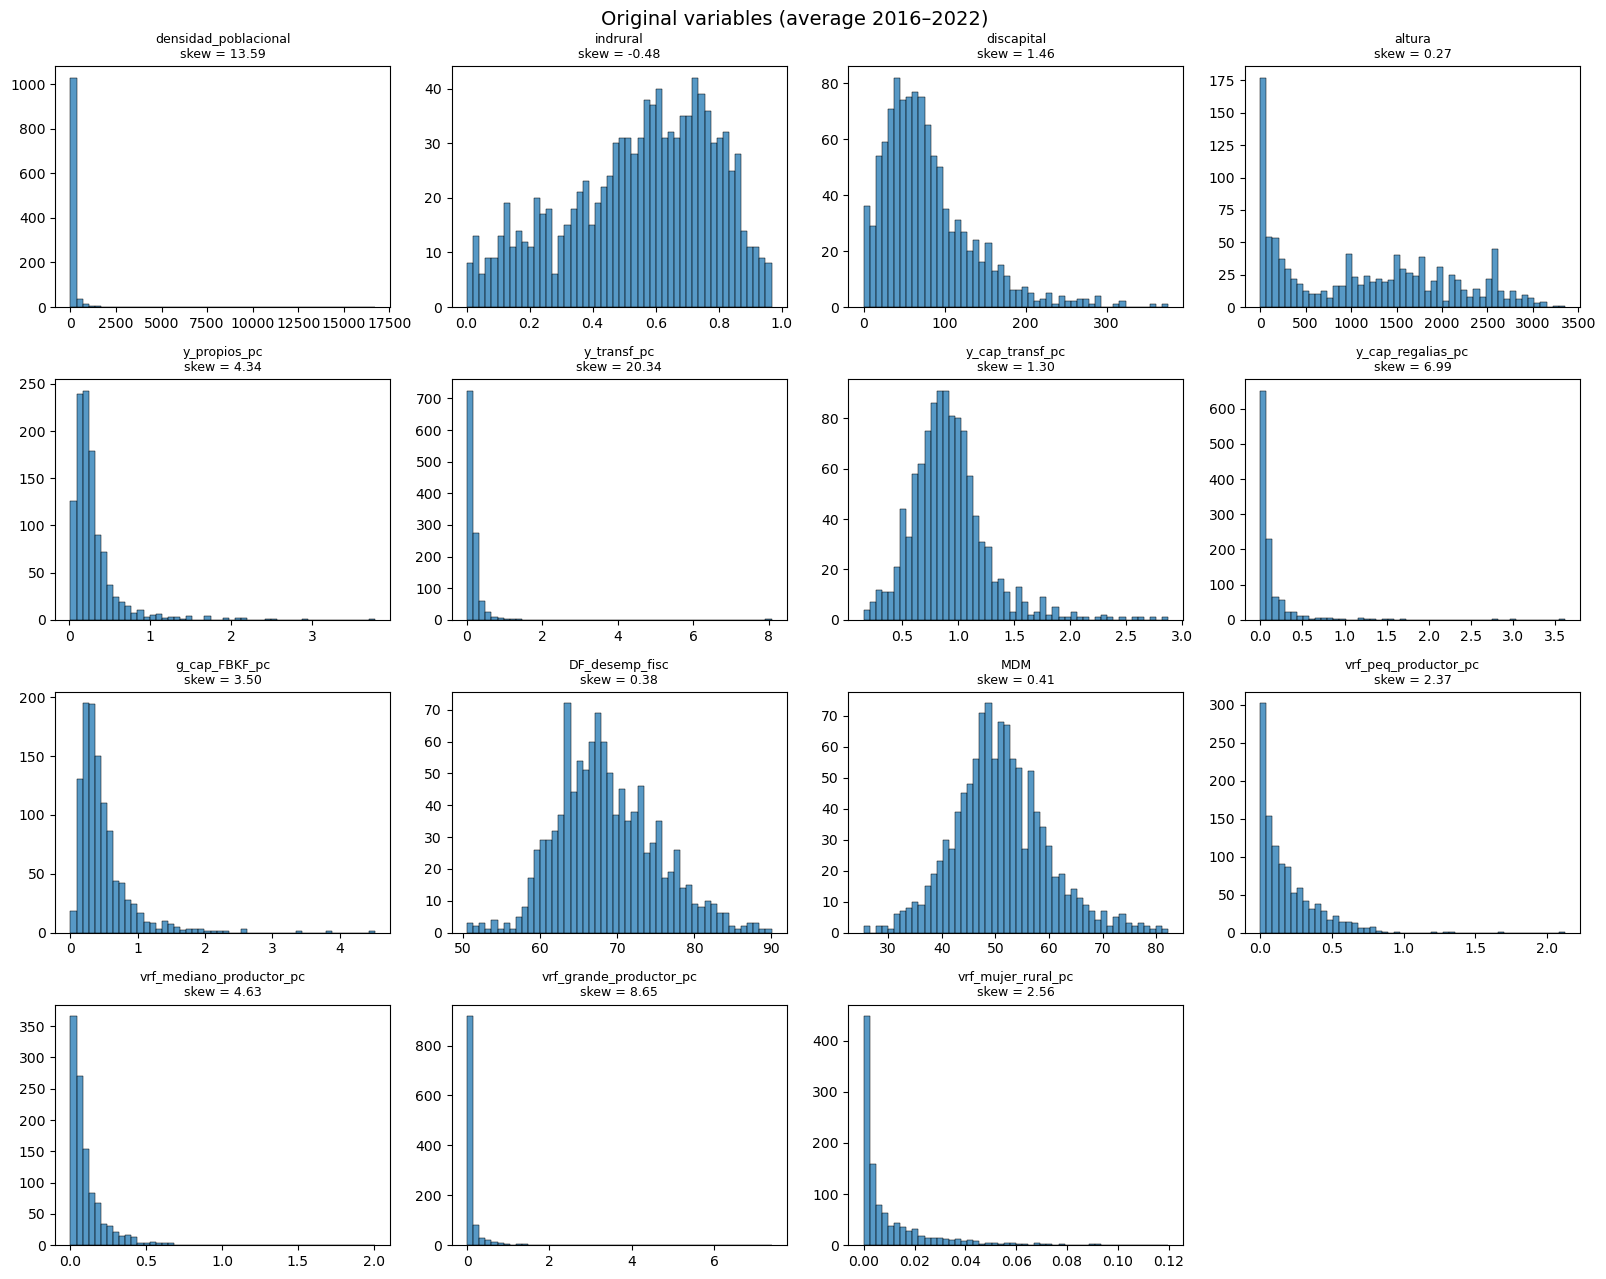

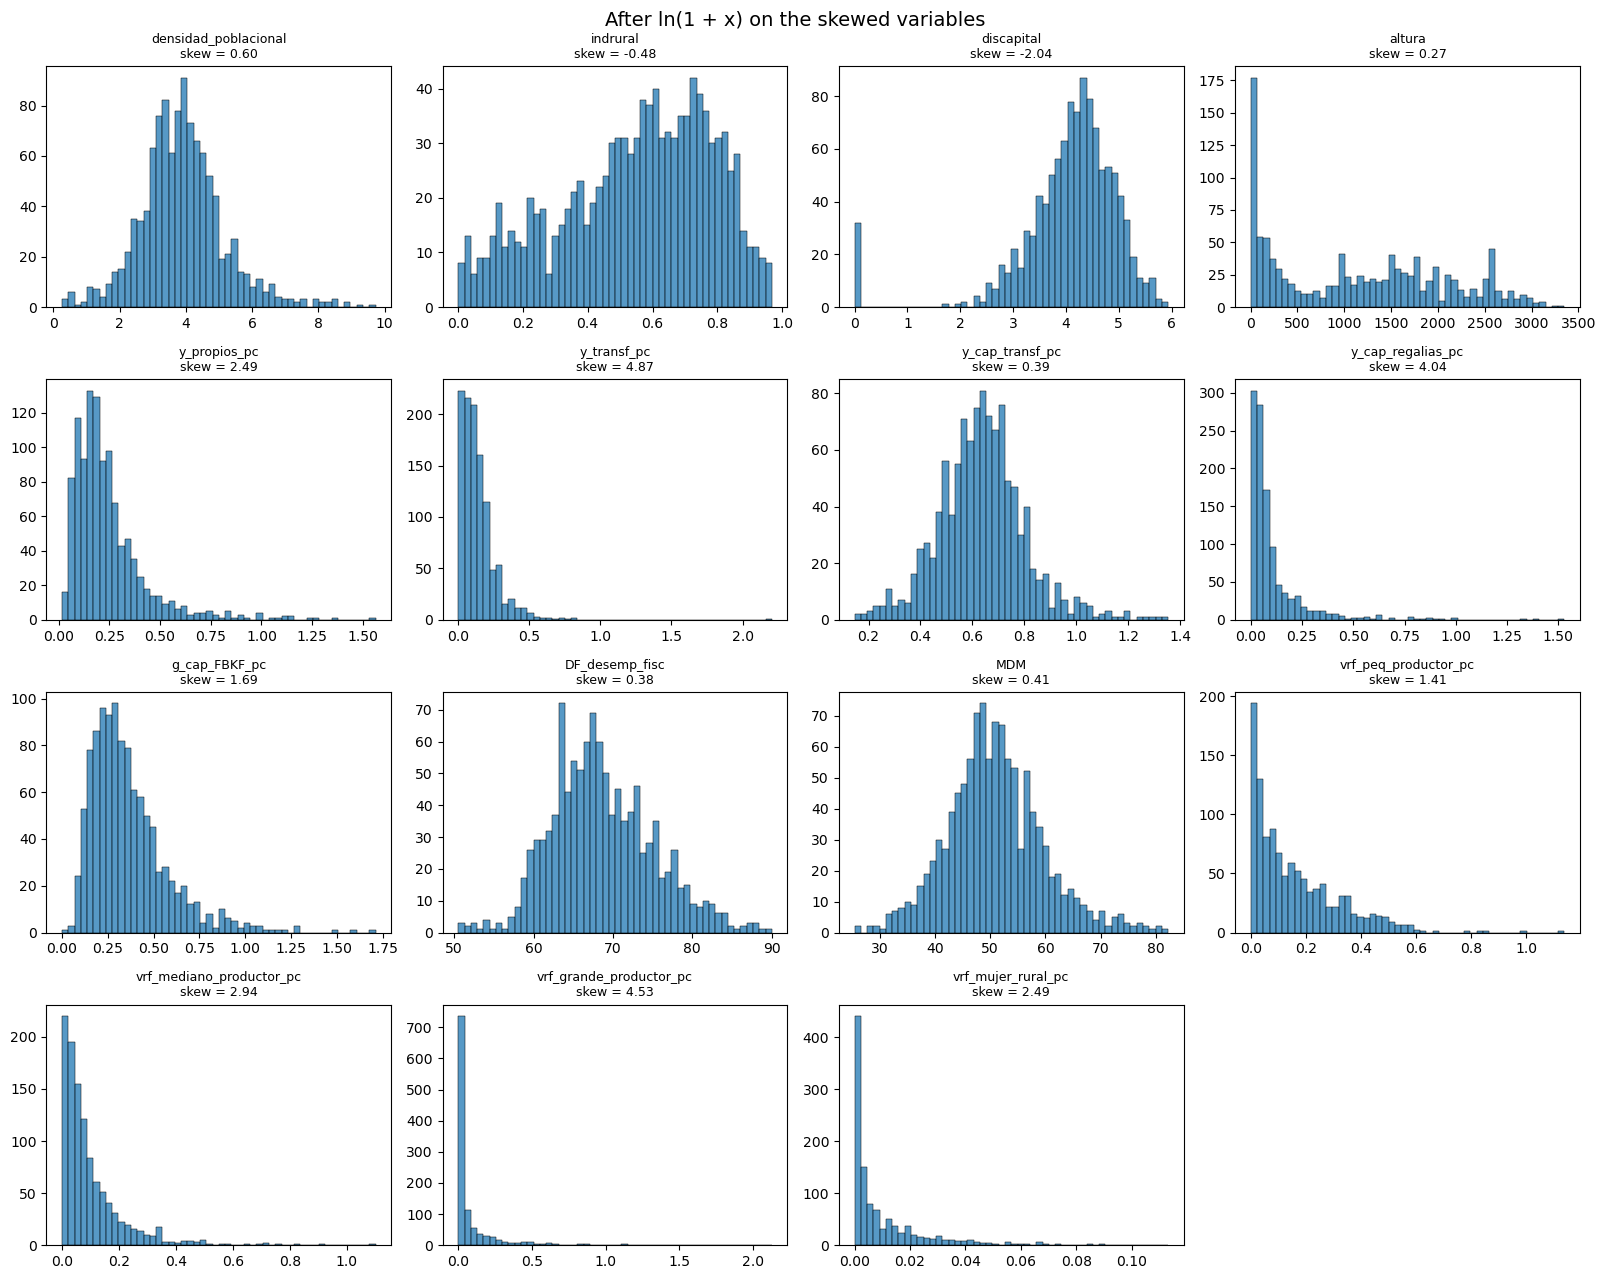

In [66]:
def histogram_grid(data, title, bins=50):
    fig, axes = plt.subplots(4, 4, figsize=(16, 13))
    axes = axes.ravel()
    for ax, var in zip(axes, pca_variables):
        sns.histplot(data[var], bins=bins, ax=ax, color="tab:blue")
        ax.set_title(f"{var}\nskew = {data[var].skew():.2f}", fontsize=9)
        ax.set_xlabel("")
        ax.set_ylabel("")
    for ax in axes[len(pca_variables):]:
        ax.set_visible(False)
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

histogram_grid(df_2016_2022_needed, "Original variables (average 2016–2022)")
histogram_grid(X, "After ln(1 + x) on the skewed variables")



In [15]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
densidad_poblacional,1102.0,3.898083,1.269749,0.265102,3.139164,3.842243,4.552866,9.724084
indrural,1102.0,0.549633,0.233704,0.001392,0.388313,0.584294,0.734150,0.967549
discapital,1102.0,4.073244,0.977695,0.000000,3.716069,4.214992,4.646824,5.932559
altura,1102.0,1149.706897,918.486382,1.000000,200.000000,1123.500000,1850.000000,3350.000000
y_propios_pc,1102.0,0.243584,0.182895,0.016207,0.129523,0.196866,0.292369,1.563060
y_transf_pc,1102.0,0.140434,0.131100,0.001637,0.055856,0.113157,0.180858,2.205141
y_cap_transf_pc,1102.0,0.636096,0.166174,0.145989,0.539459,0.634402,0.725210,1.353800
y_cap_regalias_pc,1102.0,0.103820,0.150713,0.000000,0.028059,0.056585,0.112759,1.528979
g_cap_FBKF_pc,1102.0,0.363960,0.212037,0.001608,0.217590,0.316805,0.455967,1.709337
DF_desemp_fisc,1102.0,68.659404,6.430324,50.505024,63.987981,67.883723,72.718526,90.010238


## 3. Normalization

The variables have different units (km, meters, index points, millions of pesos), so their variances are not comparable: altitude varies in thousands, rurality between 0 and 1. Without normalizing, altitude would dominate the PCA only because of its unit. Each variable is standardized as follows:

$$
z_{ij} = \frac{x_{ij} - \bar{x}_j}{s_j}, \qquad \bar{x}_j = \frac{1}{n}\sum_{i=1}^{n} x_{ij}, \qquad s_j = \sqrt{\frac{1}{n-1}\sum_{i=1}^{n}(x_{ij} - \bar{x}_j)^2}
$$

In matrix form:

$$
\mathbf{Z} = (\mathbf{X} - \mathbf{1}\bar{\mathbf{x}}^T)\mathbf{D}^{-1}
$$

Where:

- $\mathbf{Z}$ is the $n \times p$ standardized data matrix ($n = 1102$ municipalities, $p = 15$ variables).
- $\mathbf{X}$ is the $n \times p$ data matrix.
- $\mathbf{1}$ is an $n \times 1$ column vector of ones, so $\mathbf{1}\bar{\mathbf{x}}^T$ repeats the vector of means in every row.
- $\bar{\mathbf{x}}$ is a $p \times 1$ column vector containing the mean of each variable.
- $\mathbf{D}$ is a $p \times p$ diagonal matrix whose diagonal contains the standard deviation of each variable; multiplying by $\mathbf{D}^{-1}$ divides each column by its standard deviation.



**1. Matrix of means.** Multiplying the column of ones by the vector of means repeats the means in every row:

$$
\mathbf{1}\bar{\mathbf{x}}^T =
\begin{bmatrix} 1 \\ 1 \\ \vdots \\ 1 \end{bmatrix}
\begin{bmatrix} \bar{x}_1 & \bar{x}_2 & \cdots & \bar{x}_p \end{bmatrix}
=
\begin{bmatrix}
\bar{x}_1 & \bar{x}_2 & \cdots & \bar{x}_p \\
\bar{x}_1 & \bar{x}_2 & \cdots & \bar{x}_p \\
\vdots & \vdots & \ddots & \vdots \\
\bar{x}_1 & \bar{x}_2 & \cdots & \bar{x}_p
\end{bmatrix}
$$

**2. Centering.** The mean of each column is subtracted from every observation in that column:

$$
\begin{aligned}
\mathbf{X} - \mathbf{1}\bar{\mathbf{x}}^T
&=
\begin{bmatrix}
x_{11} & x_{12} & \cdots & x_{1p} \\
x_{21} & x_{22} & \cdots & x_{2p} \\
\vdots & \vdots & \ddots & \vdots \\
x_{n1} & x_{n2} & \cdots & x_{np}
\end{bmatrix}
-
\begin{bmatrix}
\bar{x}_1 & \bar{x}_2 & \cdots & \bar{x}_p \\
\bar{x}_1 & \bar{x}_2 & \cdots & \bar{x}_p \\
\vdots & \vdots & \ddots & \vdots \\
\bar{x}_1 & \bar{x}_2 & \cdots & \bar{x}_p
\end{bmatrix} \\[6pt]
&=
\begin{bmatrix}
x_{11}-\bar{x}_1 & x_{12}-\bar{x}_2 & \cdots & x_{1p}-\bar{x}_p \\
x_{21}-\bar{x}_1 & x_{22}-\bar{x}_2 & \cdots & x_{2p}-\bar{x}_p \\
\vdots & \vdots & \ddots & \vdots \\
x_{n1}-\bar{x}_1 & x_{n2}-\bar{x}_2 & \cdots & x_{np}-\bar{x}_p
\end{bmatrix}
\end{aligned}
$$

**3. Matrix of standard deviations.** $\mathbf{D}$ is diagonal, so its inverse is obtained by inverting each diagonal element:

$$
\mathbf{D} =
\begin{bmatrix}
s_1 & 0 & \cdots & 0 \\
0 & s_2 & \cdots & 0 \\
\vdots & \vdots & \ddots & \vdots \\
0 & 0 & \cdots & s_p
\end{bmatrix},
\qquad
\mathbf{D}^{-1} =
\begin{bmatrix}
\frac{1}{s_1} & 0 & \cdots & 0 \\
0 & \frac{1}{s_2} & \cdots & 0 \\
\vdots & \vdots & \ddots & \vdots \\
0 & 0 & \cdots & \frac{1}{s_p}
\end{bmatrix}
$$

**4. Standardization.** Multiplying by $\mathbf{D}^{-1}$ on the right divides each column $j$ by $s_j$:

$$
\begin{aligned}
\mathbf{Z}
&=
\begin{bmatrix}
x_{11}-\bar{x}_1 & \cdots & x_{1p}-\bar{x}_p \\
x_{21}-\bar{x}_1 & \cdots & x_{2p}-\bar{x}_p \\
\vdots & \ddots & \vdots \\
x_{n1}-\bar{x}_1 & \cdots & x_{np}-\bar{x}_p
\end{bmatrix}
\begin{bmatrix}
\frac{1}{s_1} & \cdots & 0 \\
\vdots & \ddots & \vdots \\
0 & \cdots & \frac{1}{s_p}
\end{bmatrix} \\[6pt]
&=
\begin{bmatrix}
\dfrac{x_{11}-\bar{x}_1}{s_1} & \dfrac{x_{12}-\bar{x}_2}{s_2} & \cdots & \dfrac{x_{1p}-\bar{x}_p}{s_p} \\[8pt]
\dfrac{x_{21}-\bar{x}_1}{s_1} & \dfrac{x_{22}-\bar{x}_2}{s_2} & \cdots & \dfrac{x_{2p}-\bar{x}_p}{s_p} \\[8pt]
\vdots & \vdots & \ddots & \vdots \\[4pt]
\dfrac{x_{n1}-\bar{x}_1}{s_1} & \dfrac{x_{n2}-\bar{x}_2}{s_2} & \cdots & \dfrac{x_{np}-\bar{x}_p}{s_p}
\end{bmatrix}
\end{aligned}
$$

After this step every variable has mean 0 and standard deviation 1, so all of them weigh the same.


In [67]:
Z = (X - X.mean()) / X.std(ddof=1)
Z.aggregate(["mean", "std"]).round(1)

,densidad_poblacional,indrural,discapital,altura,y_propios_pc,y_transf_pc,y_cap_transf_pc,y_cap_regalias_pc,g_cap_FBKF_pc,DF_desemp_fisc,MDM,vrf_peq_productor_pc,vrf_mediano_productor_pc,vrf_grande_productor_pc,vrf_mujer_rural_pc
mean,0.0,0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0,-0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 4. PCA

### 4.1 Covariance matrix

$$
\mathbf{S} = \frac{1}{n-1} \mathbf{Z}^T \mathbf{Z}
$$

$\mathbf{S}$ is $p \times p$ ($15 \times 15$). Its entry $s_{jk} = \frac{1}{n-1}\sum_i z_{ij} z_{ik}$ is the covariance between standardized variables $j$ and $k$, which equals their correlation. The diagonal is all ones. 
$$
\text{tr}(\mathbf{S}) = \sum_{j=1}^{p} s_{jj} = p = 15
$$

Trace of S (total variance): 15.0


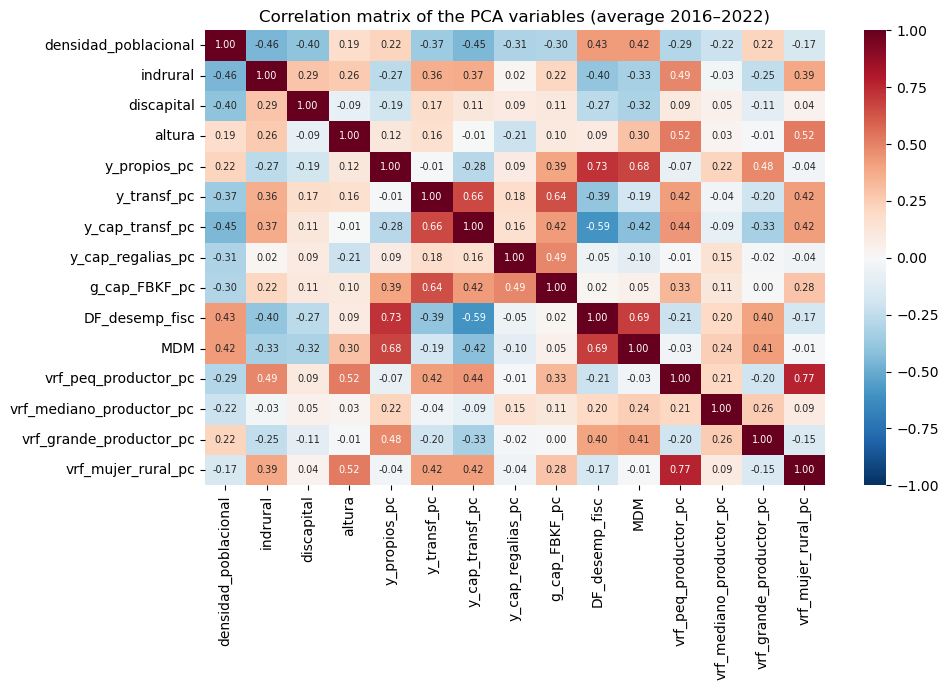

In [20]:
n = Z.shape[0]
S = (Z.T @ Z) / (n - 1)

print("Trace of S (total variance):", round(np.trace(S), 4))

plt.figure(figsize=(10, 7))
sns.heatmap(S, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlation matrix of the PCA variables (average 2016–2022)")
plt.tight_layout()
plt.show()

### 4.2 Eigenvalues and eigenvectors

In PCA we looks for the direction $\mathbf{v}$ ($p \times 1$ vector) along which the projected data $\mathbf{Z}\mathbf{v}$ have maximum variance. Each element of $\mathbf{Z}\mathbf{v}$ is a weighted sum of the 15 standardized variables of one municipality.

columns of $\mathbf{Z}$ have mean $0$, so $\mathbf{Z}\mathbf{v}$ also has mean $0$ and its variance is

$$
\text{Var}(\mathbf{Z}\mathbf{v}) = \frac{1}{n-1}(\mathbf{Z}\mathbf{v})^T(\mathbf{Z}\mathbf{v}) = \mathbf{v}^T\left(\frac{1}{n-1}\mathbf{Z}^T\mathbf{Z}\right)\mathbf{v} = \mathbf{v}^T\mathbf{S}\mathbf{v}
$$

But if we solve without a restriction the variance could be made as large as we want just by multiplying $\mathbf{v}$ by a big number, so $\mathbf{v}$ is required to have length $1$

$$
\max_{\mathbf{v}} \ \mathbf{v}^T \mathbf{S} \mathbf{v} \quad \text{subject to} \quad \mathbf{v}^T\mathbf{v} = 1
$$

Solving the optimization problem with a lagrangian:

$$
\mathcal{L}(\mathbf{v}, \lambda) = \mathbf{v}^T\mathbf{S}\mathbf{v} - \lambda(\mathbf{v}^T\mathbf{v} - 1)
$$


$$
\mathbf{S}\mathbf{v} = \lambda \mathbf{v}
$$

So by calculus we get the definition of an **eigenvector** wich is the optimal direction $\mathbf{v}$  and the  eigenvector of $\mathbf{S}$ and the multiplier $\lambda$ is its **eigenvalue**. Written as $(\mathbf{S} - \lambda\mathbf{I})\mathbf{v} = \mathbf{0}$, a solution with $\mathbf{v} \neq \mathbf{0}$ exists only if $\det(\mathbf{S} - \lambda\mathbf{I}) = 0$, which gives the $p$ eigenvalues.

Given that:

$$
\mathbf{v}^T\mathbf{S}\mathbf{v} = \lambda\,\mathbf{v}^T\mathbf{v} = \lambda
$$

the variance along each eigenvector is exactly its eigenvalue. 

So to maximize the variance we pick the eigenvector with the **largest** eigenvalue: $\mathbf{v}_1$ with $\lambda_1$. **This is the first principal component**.


**All components together.** Putting the $p$ equations $\mathbf{S}\mathbf{v}_j = \lambda_j\mathbf{v}_j$ side by side gives $\mathbf{S}\mathbf{V} = \mathbf{V}\mathbf{\Lambda}$, and since $\mathbf{V}^{-1} = \mathbf{V}^T$:

$$
\mathbf{S} = \mathbf{V} \mathbf{\Lambda} \mathbf{V}^T
$$



In [68]:
eigenvalues, eigenvectors = np.linalg.eigh(S)

order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]



### 4.3 Proportion of variance of each component

Since $\sum_j \lambda_j = \text{tr}(\mathbf{S}) = p$, the share of the total variance captured by component $j$ is

$$
\text{PVE}_j = \frac{\lambda_j}{\sum_{k=1}^{p} \lambda_k} = \frac{\lambda_j}{15}
$$

In [72]:
explained_variance_ratio = eigenvalues / eigenvalues.sum()

variance_table = pd.DataFrame({
    "eigenvalue": eigenvalues,
    "explained": explained_variance_ratio,
    "cumulative": explained_variance_ratio.cumsum()
}, index=[f"PC{i+1}" for i in range(len(eigenvalues))])
variance_table.round(3)

,eigenvalue,explained,cumulative
PC1,4.476,0.298,0.298
PC2,2.781,0.185,0.484
PC3,1.927,0.128,0.612
PC4,1.250,0.083,0.696
PC5,0.868,0.058,0.753
PC6,0.747,0.050,0.803
PC7,0.597,0.040,0.843
PC8,0.560,0.037,0.880
PC9,0.437,0.029,0.910
PC10,0.324,0.022,0.931


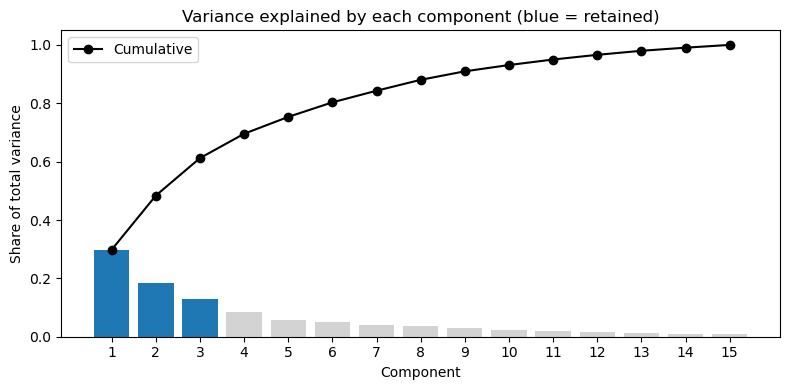

In [70]:
fig, ax = plt.subplots(figsize=(8, 4))
pcs = np.arange(1, len(eigenvalues) + 1)
ax.bar(pcs, explained_variance_ratio, color=["tab:blue"] * 3 + ["lightgrey"] * (len(pcs) - 3))
ax.plot(pcs, explained_variance_ratio.cumsum(), marker="o", color="black", label="Cumulative")
ax.set_xticks(pcs)
ax.set_xlabel("Component")
ax.set_ylabel("Share of total variance")
ax.set_title("Variance explained by each component (blue = retained)")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Reduction to three components

The coordinates (scores) of each municipality are obtained by projecting the standardized data onto the first 3 eigenvectors:

$$
\mathbf{Y} = \mathbf{Z}\mathbf{V}_3
$$

Here, $\mathbf{Z}$ is $n \times 15$, $\mathbf{V}_3$ contains the first three columns of $\mathbf{V}$ and is $15 \times 3$, and $\mathbf{Y}$ is $n \times 3$.

If we expand the matrix product we can see that each principal component is a linear combination of the 15 standardized variables, with weights given by the corresponding eigenvector. 

For example, the first column of $\mathbf{Y}$ is:

$$
\mathbf{Y}_{\cdot 1}
=
v_{11}\mathbf{Z}_{\cdot 1}
+
v_{21}\mathbf{Z}_{\cdot 2}
+\cdots+
v_{15,1}\mathbf{Z}_{\cdot 15}.
$$

Here, $\mathbf{Z}_{\cdot l}$ denotes the column containing the standardized values of variable $l$ for all municipalities.

For an individual municipality $i$, its score on component $j$ is:

$$
y_{ij}
=
\sum_{l=1}^{15} z_{il}v_{lj},
\qquad j=1,2,3.
$$

Thus, row $i$ of $\mathbf{Y}$ contains the three new coordinates $(y_{i1}, y_{i2}, y_{i3})$ of municipality $i$.

In [74]:
k = 3
pc_names = [f"PC{i+1}" for i in range(k)]
V3 = eigenvectors[:, :k] #i keep the first k eigenvectors (Columns) 

scores = pd.DataFrame(Z.to_numpy() @ V3, index=Z.index, columns=pc_names)

print("Variance of the scores:", scores.var(ddof=1).round(3).tolist())
print("Eigenvalues:           ", eigenvalues[:k].round(3).tolist())
print("Covariance between scores (off-diagonal ≈ 0):")
print(scores.cov().round(3))
scores.head() 

Variance of the scores: [4.476, 2.781, 1.927]
Eigenvalues:            [4.476, 2.781, 1.927]
Covariance between scores (off-diagonal ≈ 0):
       PC1    PC2    PC3
PC1  4.476 -0.000  0.000
PC2 -0.000  2.781  0.000
PC3  0.000  0.000  1.927


,PC1,PC2,PC3
0,-6.526545,2.519236,-1.214426
1,-0.217535,0.239449,-0.796575
2,1.883727,-0.091622,0.580585
3,0.612787,0.163758,0.283204
4,-3.772759,0.649522,-0.382597


## 6. Information retained and lost

**Retained** variance with three components:

$$
\text{Retained} = \frac{\lambda_1 + \lambda_2 + \lambda_3}{\sum_{j=1}^{15} \lambda_j} = \frac{4.476+2.781+1.927}{15} \approx 0.612, \qquad \text{Lost} = 1 - \text{Retained} = \frac{\sum_{j=4}^{15} \lambda_j}{\sum_{j=1}^{15} \lambda_j} \approx 0.387 
$$



In [75]:
retained = eigenvalues[:k].sum() / eigenvalues.sum()
lost = 1 - retained

print(f"retained:{retained:.1%}")
print(f"lost:{lost:.1%}")



retained:61.2%
lost:38.8%


**Information retained  by variable**

For each standardized variable $l$, we multiply its squared eigenvector coefficients by the corresponding eigenvalues, element by element:

$$
(v_{l1}^{2},\,v_{l2}^{2},\,v_{l3}^{2})
\odot
(\lambda_1,\,\lambda_2,\,\lambda_3)
=
(\lambda_1v_{l1}^{2},\,\lambda_2v_{l2}^{2},\,\lambda_3v_{l3}^{2}),
$$

where $\odot$ denotes element multiplication. 

We then sum these three contributions to obtain the retained variance of variable $l$:

$$
c_l
=
\sum_{j=1}^{3}\lambda_jv_{lj}^{2}
=
\lambda_1v_{l1}^{2}
+
\lambda_2v_{l2}^{2}
+
\lambda_3v_{l3}^{2}.
$$

Since each standardized variable has variance 1, $c_l$ is the proportion of its variance retained by the first three components.

In [76]:
communality = pd.Series((V3**2 * eigenvalues[:k]).sum(axis=1), index=pca_variables, name="retained_per_variable")
communality.sort_values().round(2)

discapital                  0.22
vrf_mediano_productor_pc    0.23
vrf_grande_productor_pc     0.41
indrural                    0.50
y_cap_regalias_pc           0.56
densidad_poblacional        0.61
y_transf_pc                 0.63
y_cap_transf_pc             0.64
altura                      0.72
vrf_mujer_rural_pc          0.75
MDM                         0.77
g_cap_FBKF_pc               0.77
DF_desemp_fisc              0.78
vrf_peq_productor_pc        0.79
y_propios_pc                0.81
Name: retained_per_variable, dtype: float64

The three components keep **61.2%** of the total variance and lose **38.8%**. The last table shows the share of each variable's variance kept by PC1–PC3, $\ h_j^2 = \sum_{c=1}^{3} \lambda_c v_{jc}^2$. The best represented are own revenue (81%), credit to small producers (79%), fiscal performance (78%), MDM and fixed capital investment (77% each). The worst are distance to the capital (22%), credit to medium producers (23%) and credit to large producers (41%): most of their variance lies in the discarded components.

## 7. Interpretation of the components

### 7.1 Which variables contribute to each component

Two complementary measures:

- **Loadings** (correlation between variable $j$ and component $c$):

$$
\ell_{jc} = v_{jc}\sqrt{\lambda_c}, \qquad \mathbf{L} = \mathbf{V}_3\mathbf{\Lambda}_3^{1/2}
$$

  Since $\text{Var}(z_j) = 1$ and $\text{Var}(y_c) = \lambda_c$, $\ \text{Corr}(z_j, y_c) = \frac{\text{Cov}(z_j, y_c)}{\sqrt{\lambda_c}} = \frac{\lambda_c v_{jc}}{\sqrt{\lambda_c}} = v_{jc}\sqrt{\lambda_c}$. The sign tells the direction of the relationship.

- **Contribution** (%) of variable $j$ to component $c$:

$$
\text{ctr}_{jc} = v_{jc}^2 \times 100
$$

  Because each eigenvector has unit length, $\sum_j v_{jc}^2 = 1$, so the contributions of the 15 variables add up to 100%. With 15 variables the average contribution is $100/15 \approx 6.7\%$; variables above that threshold are the ones that define the component.

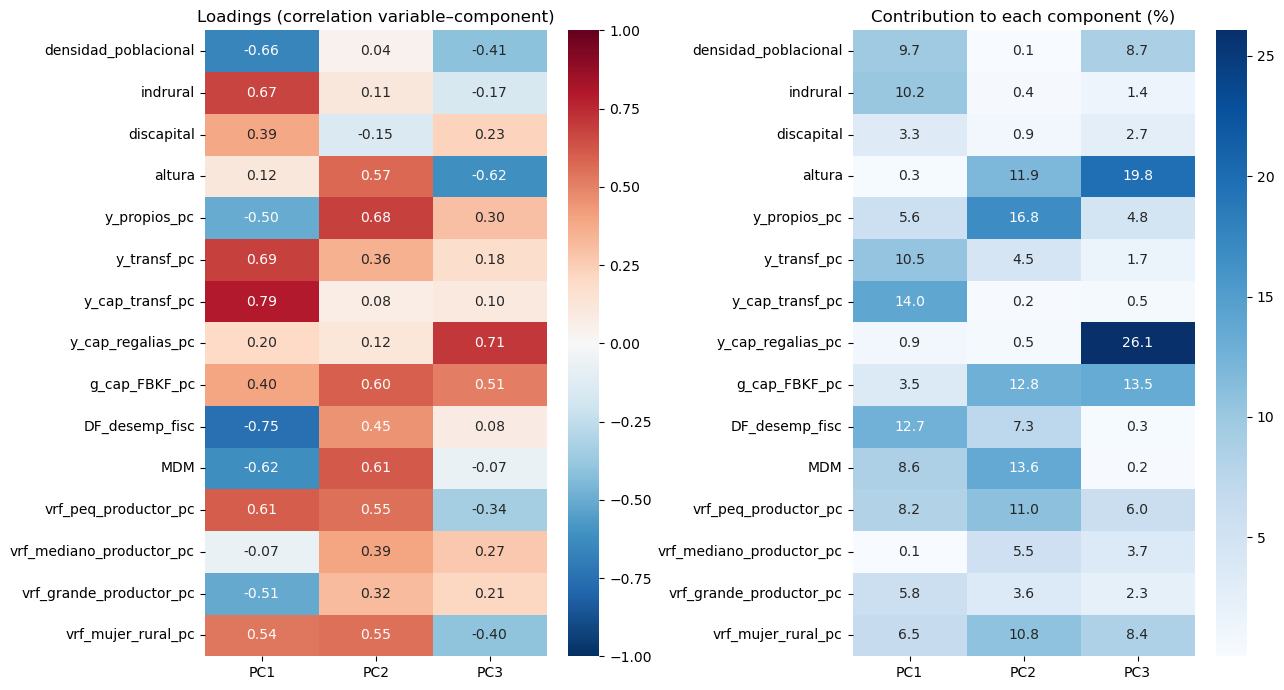

In [77]:
loadings = pd.DataFrame(V3 * np.sqrt(eigenvalues[:k]), index=pca_variables, columns=pc_names)
contributions = pd.DataFrame(V3**2 * 100, index=pca_variables, columns=pc_names)

fig, axes = plt.subplots(1, 2, figsize=(13, 7))
sns.heatmap(loadings, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", ax=axes[0])
axes[0].set_title("Loadings (correlation variable–component)")
sns.heatmap(contributions, cmap="Blues", annot=True, fmt=".1f", ax=axes[1])
axes[1].set_title("Contribution to each component (%)")
plt.tight_layout()
plt.show()


### PC1 ($29.8\%$) — Rurality and transfers vs. urban fiscal capacity

The largest contributions come from capital transfers ($14.0\%$), fiscal performance ($12.7\%$), current transfers ($10.5\%$), rurality ($10.2\%$), and population density ($9.7\%$).

PC1 has positive loadings for capital transfers ($0.79$), current transfers ($0.69$), rurality ($0.67$), credit to small producers ($0.61$), and credit to rural women ($0.54$). Negative loadings correspond to fiscal performance ($-0.75$), population density ($-0.66$), MDM ($-0.62$), credit to large producers ($-0.51$), and own revenue ($-0.50$).

**Higher PC1 scores** are associated with greater rurality, higher transfers per capita, and more credit per capita to small producers and rural women. **Lower PC1 scores** are associated with greater population density, higher own revenue per capita, higher fiscal-performance and MDM scores, and more credit per capita to large producers.


### PC2 ($18.5\%$) — Local capacity, investment and smallholder credit

The largest contributions come from own revenue ($16.8\%$), MDM ($13.6\%$), fixed capital investment ($12.8\%$), altitude ($11.9\%$), credit to small producers ($11.0\%$), and credit to rural women ($10.8\%$).

All these variables have positive loadings: own revenue ($0.68$), MDM ($0.61$), fixed capital investment ($0.60$), altitude ($0.57$), small-producer credit ($0.55$), and rural-women credit ($0.55$). Fiscal performance also has a positive loading ($0.45$).

**Higher PC2 scores** are associated with higher own revenue and fixed capital investment per capita, higher MDM and fiscal-performance scores, higher altitude, and more credit per capita to small producers and rural women. **Lower PC2 scores** tend to reflect lower values in this group of characteristics.


### PC3 ($12.8\%$) — Royalties and investment vs. altitude and rural credit

The largest contributions come from royalties ($26.1\%$), altitude ($19.8\%$), and fixed capital investment ($13.5\%$), followed by population density ($8.7\%$) and credit to rural women ($8.4\%$).

PC3 has positive loadings for royalties ($0.71$) and fixed capital investment ($0.51$). Negative loadings correspond to altitude ($-0.62$), population density ($-0.41$), credit to rural women ($-0.40$), and credit to small producers ($-0.34$).

**Higher PC3 scores** are associated with higher royalties and fixed capital investment per capita, lower altitude, lower population density, and less credit per capita to rural women and small producers. **Lower PC3 scores** are associated with the opposite pattern, particularly higher altitude and lower royalties per capita.

## 8. Component plots and violence against social leaders

For each municipality, I sum recorded killings over 2018–2023 and divide by its average population in those six years:

$$
r_i = \frac{\sum_{t=2018}^{2023} D_{it}}{\overline{P}_i}\times100{,}000.
$$

This is a **cumulative rate for 2018–2023**, calculated using mean population. Each point in the following plots is a municipality. Red identifies at least one recorded killing during the period; grey identifies zero recorded killings. Labels mark the minimum and maximum scores on each displayed axis.


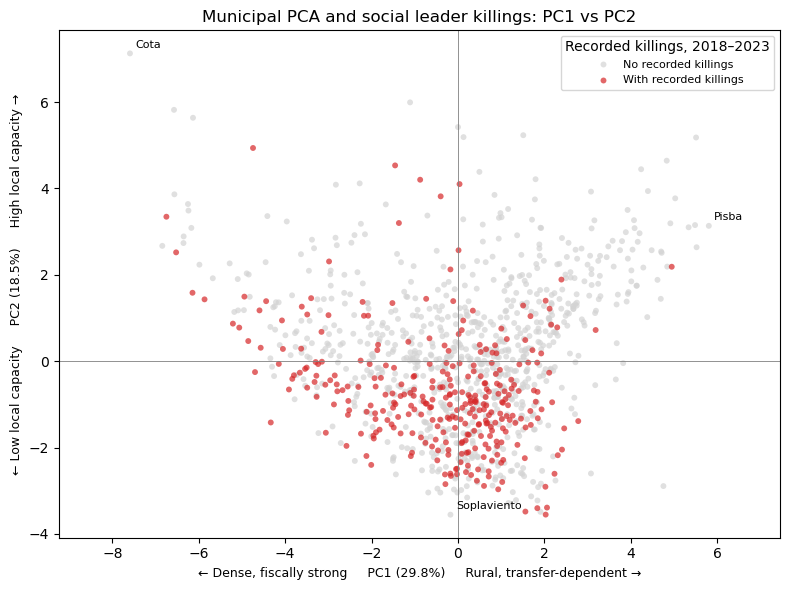

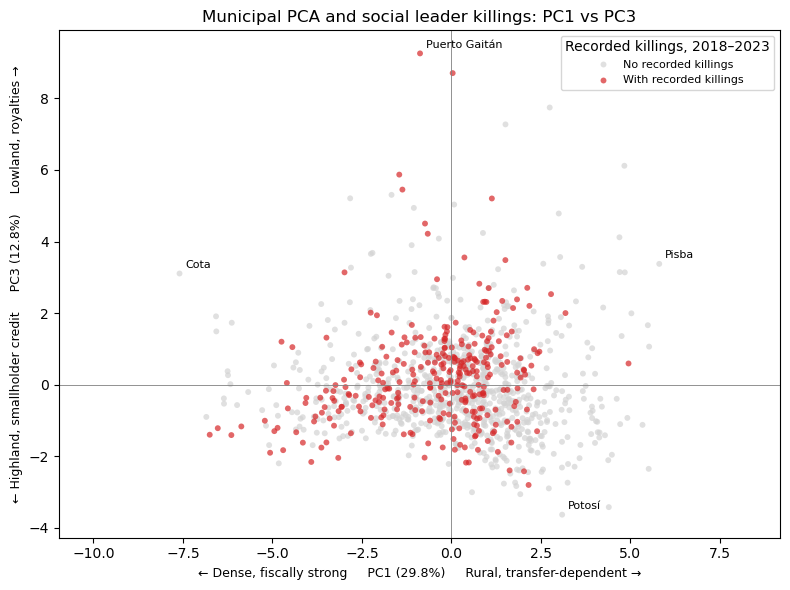

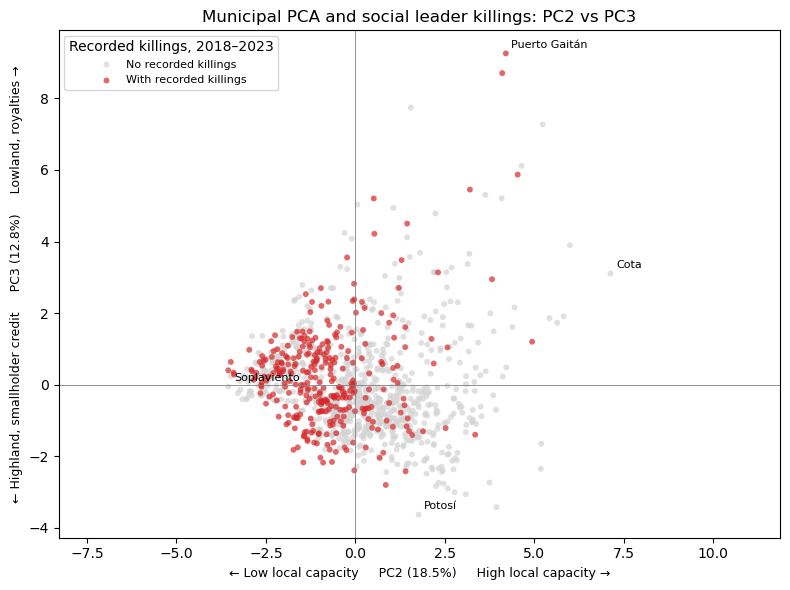

In [80]:
# Recorded killings and population, 2018–2023
violence = (
    panel_municipal_tierras[
        panel_municipal_tierras["anio"].between(2018, 2023)
    ]
    .groupby("cod_municipio")
    .agg(
        lideres_2018_2023=("n_lideres_asesinados_SD", "sum"),
        pobl_media=("pobl_tot", "mean")
    )
)
violence["tasa_100k"] = (
    violence["lideres_2018_2023"] / violence["pobl_media"] * 100000
)

# Municipality identifiers, PCA scores, and violence
results = df_2016_2022_needed.loc[
    scores.index,
    ["cod_municipio", "nombre_departamento", "nombre_municipio"]
].join(scores).join(violence, on="cod_municipio")

results["violencia"] = np.where(
    results["lideres_2018_2023"] > 0,
    "With recorded killings", "No recorded killings"
)

directions = {
    "PC1": ("Dense, fiscally strong", "Rural, transfer-dependent"),
    "PC2": ("Low local capacity", "High local capacity"),
    "PC3": ("Highland, smallholder credit", "Lowland, royalties"),
}

for pc_x, pc_y in [("PC1", "PC2"), ("PC1", "PC3"), ("PC2", "PC3")]:
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.scatterplot(
        data=results.sort_values("lideres_2018_2023"),
        x=pc_x, y=pc_y, hue="violencia",
        hue_order=["No recorded killings", "With recorded killings"],
        palette={"No recorded killings": "lightgrey",
                 "With recorded killings": "tab:red"},
        s=18, alpha=0.7, linewidth=0, ax=ax
    )

    # Identify the lowest and highest scores on each axis
    extremes = [
        results[pc_x].idxmin(), results[pc_x].idxmax(),
        results[pc_y].idxmin(), results[pc_y].idxmax()
    ]
    for idx in set(extremes):
        ax.annotate(
            results.loc[idx, "nombre_municipio"],
            (results.loc[idx, pc_x], results.loc[idx, pc_y]),
            xytext=(4, 4), textcoords="offset points", fontsize=8
        )

    ax.axhline(0, color="grey", linewidth=0.6)
    ax.axvline(0, color="grey", linewidth=0.6)

    # Axis labels with the meaning of each direction
    neg_x, pos_x = directions[pc_x]
    neg_y, pos_y = directions[pc_y]
    ax.set_xlabel(
        f"← {neg_x}     {pc_x} ({variance_table.loc[pc_x, 'explained']:.1%})     {pos_x} →",
        fontsize=9
    )
    ax.set_ylabel(
        f"← {neg_y}     {pc_y} ({variance_table.loc[pc_y, 'explained']:.1%})     {pos_y} →",
        fontsize=9
    )

    ax.set_title(f"Municipal PCA and social leader killings: {pc_x} vs {pc_y}")
    ax.set_aspect("equal", adjustable="datalim")
    ax.legend(title="Recorded killings, 2018–2023", fontsize=8)
    plt.tight_layout()
    plt.show()


- PC1–PC2 (48.4% of total variance). The horizontal axis goes from dense municipalities with fiscal capacity (left, Cota at the extreme) to rural, transfer-dependent ones (right, Pisba at the extreme). The vertical axis goes from low local capacity (bottom, Soplaviento) to high own revenue, management, investment and smallholder credit (top, Cota). Red points appear across the whole PC1 axis but are clearly concentrated below zero on PC2, while the upper-right area (rural municipalities with high local capacity) is mostly grey. Rurality alone does not seem to separate violence; low local capacity does.
- PC1–PC3 (42.7%). The vertical axis adds the contrast between lowland municipalities with royalties and investment (top) and highland municipalities with smallholder credit (bottom). Red and grey points are much more mixed in this plane, with somewhat more red points above zero on PC3. The extremes illustrate the contrast: Puerto Gaitán, the oil municipality at the top of PC3, recorded killings, while Potosí, at the highland end, did not.
- PC2–PC3 (31.4%). This plane confirms that PC2 is the clearest dividing line. Red points are concentrated on the negative side of PC2 at every level of PC3, while the positive side, especially below zero on PC3 (high capacity, highland, without royalties), is mostly grey. Some red cases appear with positive PC2 and high PC3, among the royalty municipalities.


Now I will run a regression to measure how much the killing rate changes when a municipality moves along each component, and whether that relationship survives once I compare municipalities that are otherwise similar.

The outcome $r_i$ is the cumulative rate of recorded social leader killings per 100,000 inhabitants during 2018–2023, in levels.

**Standardized components.** The scores $y_{ic}$ from section 5 have mean $0$ and variance $\lambda_c$. To make the coefficients comparable across components, I divide each score by its standard deviation:

$$
\widetilde{\mathrm{PC}}_{ic} = \frac{y_{ic} - \bar{y}_c}{\sqrt{\lambda_c}} = \frac{y_{ic}}{\sqrt{\lambda_c}}, \qquad c = 1, 2, 3,
$$

so that $\widetilde{\mathrm{PC}}_{ic}$ has mean $0$ and variance $1$. In matrix form, $\widetilde{\mathbf{P}} = \mathbf{Z}\mathbf{V}_3\mathbf{\Lambda}_3^{-1/2}$.

The two specifications are:

$$
\begin{aligned}
(1)\quad r_i &= \alpha+\sum_{c=1}^3\beta_c\,\widetilde{\mathrm{PC}}_{ic}+\varepsilon_i,\\
(2)\quad r_i &= \alpha+\sum_{c=1}^3\beta_c\,\widetilde{\mathrm{PC}}_{ic}
+\gamma_1\mathrm{PDET}_i+\gamma_2\mathrm{PNIS}_i
+\delta_{d(i)}+\varepsilon_i.
\end{aligned}
$$

Here $\delta_{d(i)}$ denotes department fixed effects. Each $\beta_c$ is the change in killings per 100,000 inhabitants associated with an increase of **one standard deviation** in component $c$. Standard errors are clustered by department.


In [62]:
import statsmodels.formula.api as smf
from statsmodels.iolib.summary2 import summary_col

datos = results.copy()
datos[["pdet", "pnis"]] = df_2016_2022_needed.loc[datos.index, ["pdet", "pnis"]]
datos = datos.dropna(subset=[
    "tasa_100k", "PC1", "PC2", "PC3", "pdet", "pnis", "nombre_departamento"
])

# Standardize the scores: dividing by sqrt(lambda_c) gives variance 1 (mean is already 0)
for c, pc in enumerate(["PC1", "PC2", "PC3"]):
    datos[pc] = datos[pc] / np.sqrt(eigenvalues[c])


formulas = [
    "tasa_100k ~ PC1 + PC2 + PC3",
    "tasa_100k ~ PC1 + PC2 + PC3 + pdet + pnis + C(nombre_departamento)"
]

modelos = [
    smf.ols(f, data=datos).fit(
        cov_type="cluster",
        cov_kwds={"groups": datos["nombre_departamento"],
                  "use_correction": True, "df_correction": True},
        use_t=True
    ) for f in formulas
]

tabla = summary_col(
    modelos, model_names=["(1) Base", "(2) FE + controles"],
    stars=True, float_format="%.3f",
    regressor_order=["Intercept", "PC1", "PC2", "PC3", "pdet", "pnis"],
    drop_omitted=True,
    info_dict={
        "N": lambda m: f"{int(m.nobs)}",
        "FE departamento": lambda m: "Sí" if "C(nombre_departamento)" in m.model.formula else "No",
        "Clusters": lambda m: str(datos["nombre_departamento"].nunique())
    }
)
print(tabla)
print("Errores estándar agrupados por departamento, entre paréntesis.")



                 (1) Base (2) FE + controles
--------------------------------------------
Intercept       3.222***  -0.440            
                (0.602)   (0.379)           
PC1             0.751***  0.548**           
                (0.212)   (0.206)           
PC2             -1.451*** -0.813***         
                (0.501)   (0.207)           
PC3             1.070**   0.816**           
                (0.391)   (0.322)           
pdet                      3.867**           
                          (1.742)           
pnis                      11.403***         
                          (3.019)           
R-squared       0.054     0.320             
R-squared Adj.  0.051     0.297             
Clusters        33        33                
FE departamento No        Sí                
N               1102      1102              
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01
Errores estándar agrupados por departamento, entre paréntesis.


The data show an association between the municipal profiles and violence against social leaders. In column (1), one standard deviation more of rurality and transfer dependence (PC1) is associated with 0.75 more killings per 100,000 inhabitants, and one standard deviation more of royalties (PC3) with 1.07 more. One standard deviation more of local capacity (PC2) goes with 1.45 fewer killings. The three components together explain only 5% of the variation, so violence depends mostly on factors outside the PCA.

When municipalities of the same department are compared and PDET and PNIS are controlled for, the three associations keep their sign and remain significant. PNIS (+11.4) and PDET (+3.9) municipalities have higher rates, and $R^2$ rises to 32%. In short, killings of social leaders are higher in rural, transfer-dependent municipalities with low administrative capacity and in royalty municipalities, and this pattern holds beyond regional differences and the peace-agreement programs.